In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score


In [4]:
data=fetch_california_housing()

In [5]:
df=pd.DataFrame(data.data,columns=data.feature_names)
df['Price']=data.target
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [6]:
x=df[['AveRooms']].values
y=df['Price'].values
x

array([[6.98412698],
       [6.23813708],
       [8.28813559],
       ...,
       [5.20554273],
       [5.32951289],
       [5.25471698]], shape=(20640, 1))

In [7]:
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42)

In [16]:
print("min:", y_train.min())
print("max:", y_train.max())
print("mean:", y_train.mean())

min: 0.14999
max: 5.00001
mean: 2.071946937378876


In [8]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [24]:
w=0
b=0
epoch=1000
learning_rate=0.01
n=len(x_train_scaled)
cost_history=[]
for i in range(epoch):
    y_pred=w*x_train_scaled.flatten()+b
    dw=(1/n)*np.sum((y_train-y_pred)*x_train_scaled.flatten())
    db=(1/n)*np.sum((y_train-y_pred))
    w=w+learning_rate*dw
    b=b+learning_rate*db
    cost=(1/(2*n))*np.sum((y_train-y_pred)**2)
    cost_history.append(cost)
    if i%100==0:
        print(f"epoch{i},cost={cost:.4f}")
y_pred_gd=w*x_test_scaled.flatten()+b
print(r2_score(y_test,y_pred_gd))
print(mean_squared_error(y_test,y_pred_gd))

    
        
    
    
    
    

epoch0,cost=2.8149
epoch100,cost=0.9414
epoch200,cost=0.6904
epoch300,cost=0.6568
epoch400,cost=0.6523
epoch500,cost=0.6517
epoch600,cost=0.6516
epoch700,cost=0.6516
epoch800,cost=0.6516
epoch900,cost=0.6516
0.013798228607320828
1.292327655590046


In [25]:
x_train_ne=np.c_[np.ones((len(x_train),1)),x_train_scaled]
x_test_ne=np.c_[np.ones((len(x_test),1)),x_test_scaled]


array([[ 1.        , -0.17491646],
       [ 1.        , -0.40283542],
       [ 1.        ,  0.08821601],
       ...,
       [ 1.        , -0.60675918],
       [ 1.        ,  0.40217517],
       [ 1.        , -0.85144571]], shape=(16512, 2))

In [27]:
theta=np.linalg.inv(x_train_ne.T@x_train_ne)@(x_train_ne.T@y_train)
theta

array([2.07194694, 0.18323882])

In [30]:
y_pred_ne=x_test_ne@theta
y_pred

array([2.0398065 , 1.99804472, 2.08802048, ..., 1.9606796 , 2.14554747,
       1.91584548], shape=(16512,))

In [32]:
r2_ne=r2_score(y_test,y_pred_ne)
print(r2_ne)

0.013795337532284901


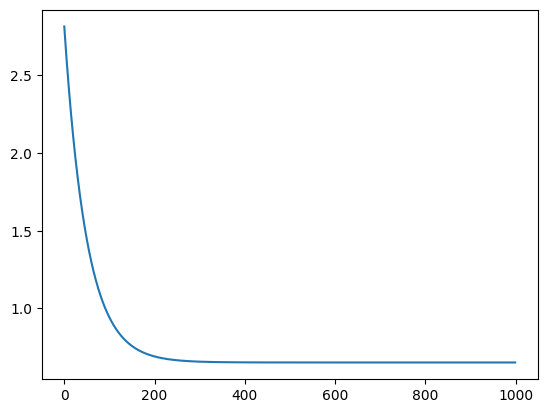

In [33]:
plt.plot(cost_history)
plt.show()

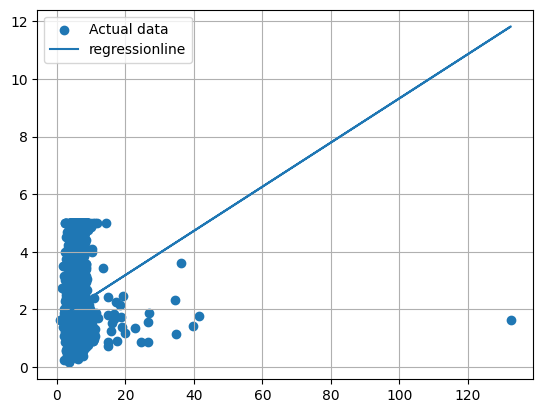

In [43]:
plt.scatter(
    x_test.flatten(),
    y_test,
label='Actual data')
plt.plot(
    x_test.flatten(),
    y_pred_gd,
label='regressionline')
plt.grid(True)
plt.legend()
plt.show()